## User case

#### Inleiding
Wij hebben een dataset via Zenodo opgezocht. Titel: Population modeling of tumor growth curves and the reduced Gompertz model improve prediction of the age of experimental tumors, PLoS Comput Biol, 16, p. e1007178. https://doi.org/10.1371/journal.pcbi.1007178 Door Vaghi C, Rodallec A, Fanciullino R, Ciccolini J, Mochel JP, et al. Uit het jaartal 2020.

Het bestaat uit 66 muizen (ID 0-65). Per muis tussen de 5 en 15 metingen. Een grotere dataset had onze voorkeur, maar was lastig te vinden. Deze dataset heeft 584 meetpunten wat ook betrouwbare resultaten kan geven.




#### Achtergrond

LM2-4 is een menselijke borstkankercellijn die sterk uitzaait. De lijn is afgeleid van MDA-MB-231, een triple-negatieve borstkankerlijn. Triple-negatief betekent dat de cellen geen oestrogeenreceptor, geen progesteronreceptor en geen HER2 hebben. Dit type borstkanker is agressief en reageert niet op hormoontherapie of anti-HER2-medicijnen. LM2-4 is geselecteerd op het vermogen om vanuit de borsttumor spontaan uit te zaaien. Daardoor is het een model voor gevorderde, uitgezaaide borstkanker.
De toevoeging LUC+ betekent dat de cellen het enzym luciferase maken, waardoor tumoren licht geven en in een levende muis te volgen zijn.

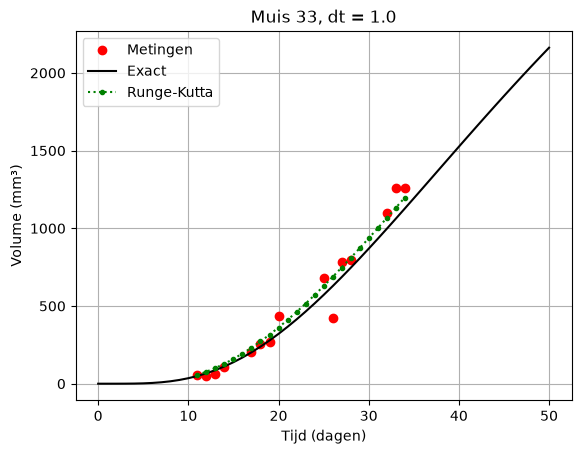

In [1]:
from package.models import *
from package.test_runge_kutta import runge_kutta  # TODO de functie voor runge_kutta uit test_runge_kutta halen
from package.random_search import random_search
from package.model_comparison import *

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
data = pd.read_csv("test_data/LM2-4LUC.txt", sep="\t")

muis33 = data[data["ID"] == 33]
muis34 = data[data["ID"] == 34]
muis35 = data[data["ID"] == 35]

In [4]:
def plot_test_data(data, marker_size = None, title = None, label = None, color = None):
    plt.scatter(x= data["Time"], y = data["Observation"], s = marker_size, label = label, c = color)
    plt.ylabel("Volume ($mm^3$)")
    plt.xlabel("Time (days) after implantation")
    plt.grid(visible = True)
    plt.ylim(bottom=0)
    plt.axvline(0.0, color='k') # maakt een verticale zwarte lijn op de x = 0
    plt.title(title)

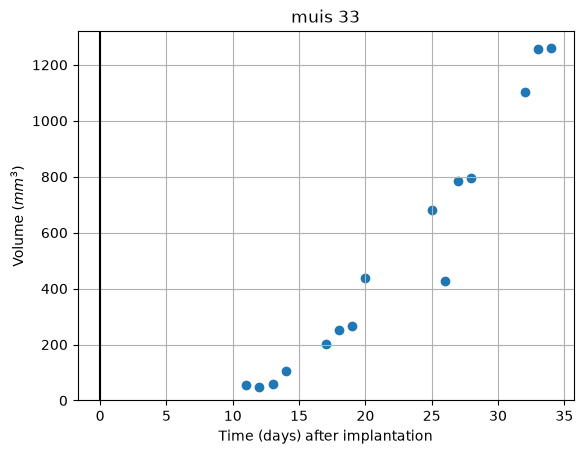

In [33]:
plot_test_data(muis33, title = "muis 33")

## Beschikbare modellen

Hieronder staan alle modellen omschreven die wij in de code uitgewerkt hebben.

In alle van de onderstaande modellen staat *V* voor de volume van de tumor.

**Exponential** model [1, 2]: 

 - $\dfrac{dV}{dt} = c \cdot V$

 - In dit model is de groeisnelheid van het volume huidige volume *V* vermenigvuldigd met de constante groeisnelheid *c* [2]. 


**Mendelsohn** model [1, 2]:

 - $\dfrac{dV}{dt} = c \cdot V^d$

 - Dit model is vergelijkbaar met de bovenstaande, maar hierbij is het volume verheven tot de macht *b*, waarbij *b* elke willekeurige waarde kan aannemen [2]. Veel tumoren groeien met b ≈ 2/3 [2]. Dit is gebaseerd op de "*surface rule model*". Dit model gaat ervan uit dat celgroei evenredig is aan het celoppervlak, wat bepalend is voor de hoeveelheid energie of voedingsstoffen die een cel kan opnemen [3].

**Logistic** model [1, 3]:

 - $\dfrac{dV}{dt} = a \cdot V \cdot (1 - \dfrac{V}{b})$

 - In dit model is sprake van een lineaire afname van de groeisnelheid van het volume. Hier is *a* de constante groeisnelheid, en *b* het maximaal tumorvolume. Dit maximale tumorvolume ontstaat doordat de concurrentie om voedingsstoffen toeneemt naarmate de tumor groeit, en door een tekort aan bloedvaten om de proliferatie van tumorcellen voor onbepaalde tijd in stand te houden [3].

**Bertalanffy** model [1, 3]:

 - $\dfrac{dV}{dt} = a \cdot V^{2/3} - b \cdot V$

 - De eerste term van deze vergelijking is verheven tot de macht 2/3. Dit is gebaseerd op de "*surface rule model*" (zie ook de uitleg van het  Mendelsohn model) [3]. Daarnaast houdt het Bertalanffy-model rekening met zowel celdeling als celsterfte via de twee termen in de vergelijking, waarbij elke term een ​​bijbehorende parameter bevat: *a* of *b* [3].

**Gompertz** model [1, 3]:

 - $\dfrac{dV}{dt} = V \cdot (a - b \cdot \ln{V})$

 - Dit model beschrijft een exponentiële afname van de groeisnelheid, evenals een maximale tumoromvang [3]. Hierin is parameter *a* een constante voor de groeisnelheid, en parameter *b* een constante voor de de afname van de groeisnelheid.

In deze notebook zal van alle beschikbare modellen een voorbeeld worden laten zien, waarbij elk model wordt gefit op de data hierboven (van muis 33).


In [6]:
t_data = muis33["Time"].values
V_data = muis33["Observation"].values

mse, params_random = random_search(t_data, V_data, bertalanffy, dt = 1)
print(mse)
print(params_random)

5599.757925023659
{'alpha': 1.230129109784151, 'beta': 0.041292209261823205}


## Modelvergelijking

BERTALANFFY
gevonden params: {'alpha': 1.234, 'beta': 0.0418}
scores: MSE = 5599.71, BIC = 137.58, AIC = 135.46, AICc = 137.64

GOMPERTZ
gevonden params: {'alpha': 0.4706, 'beta': 0.0565}
scores: MSE = 5776.93, BIC = 138.05, AIC = 135.92, AICc = 138.11

LOGISTIC
gevonden params: {'alpha': 0.2036, 'beta': 1500.1789}
scores: MSE = 7186.41, BIC = 141.32, AIC = 139.20, AICc = 141.38

EXPONENTIAL
gevonden params: {'c': 0.1408}
scores: MSE = 18755.67, BIC = 153.00, AIC = 151.59, AICc = 152.59

MENDELSOHN
gevonden params: {'c': 1.7879, 'd': 0.5541}
scores: MSE = 5564.60, BIC = 137.49, AIC = 135.36, AICc = 137.54



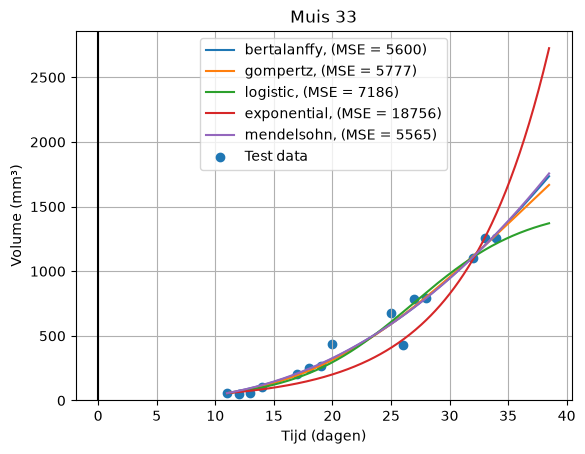

In [27]:
dt = .1
t_start = t_data[0]
V_start = V_data[0]
n_steps = 275


for model in [bertalanffy, gompertz, logistic, exponential, mendelsohn]:
    mse, params = random_search(t_data, V_data, model, dt = 1)
    ts, Vs = runge_kutta(model, t_start, V_start, dt, n_steps, **params)
    plt.plot(ts, Vs, label=f"{model.__name__}, (MSE = {mse:.0f})")

    print(model.__name__.upper())
    # parameters afronden zodat het ietsjes netter lijkt
    params_rounded = {param : round(value, ndigits=4) for param, value in params.items()}
    print(f"gevonden params: {params_rounded}")

    n = len(t_data)
    bic = BIC(mse, n, model)
    aic = AIC(mse, n, model)
    aicc = AICc(mse, n, model)
    print(f"scores: MSE = {mse:.2f}, BIC = {bic:.2f}, AIC = {aic:.2f}, AICc = {aicc:.2f}")
    print()


plot_test_data(muis33, label = "Test data")

plt.xlabel("Tijd (dagen)")
plt.ylabel("Volume (mm³)")
plt.title("Muis 33")
plt.grid(True)
plt.legend()
plt.show()

### Uitleg metrieken

Voor het vergelijken van de verschillende modellen kunnen de volgende metrieken gebruikt worden:

 - **MSE** (Mean Squarred Error). 
    - Dit laat zien hoeveel het model afwijkt van de data. Een hoge MSE betekend dat het model veel afwijkt de data [4]. Dus een lagere MSE zou kunnen betekenen dat het model beter bij de data past.
 - **BIC** (Bayes Information Criterion), **AIC** (Akaike Information Criterion) en **AICc** (Akaike Information Criterion corrected). 
    - Deze laten net als de MSE zien hoeveel het model afwijkt van de data, maar houden ook rekening met de hoeveelheid parameters die het model gebruikt. Des te meer parameters, des te hoger deze metrieken worden (het hebben van te veel parameters zou namelijk kunnen leiden tot overfitting) [5]. 
    - De 3 metrieken zijn op zichzelf niet zinvol, maar kunnen verschillen laten zien tussen de modellen [5]. Een lagere BIC/AIC/AICc betekend dat het model beter bij de data past (*verschillen tussen modellen die kleiner dan 2 zijn, zijn echter niet significant verschillend*) [5].

### Best passende model voor deze data

Op basis van deze metrieken lijkt het Mendelsohn model (met de bijbehorende gevonden parameters uiteraard) het beste te passen bij de gebruikte data, want deze heeft de laagste scores voor alle metrieken (MSE, BIC, AIC en AICc). Echter verschillen de BIC, AIC en AICc niet significant van die van het Bertalanffy model of het Gompertz model, dus deze passen ook goed. In de bovenstaande grafiek is ook goed te zien dat deze 3 modellen sterk overlappen. Van de totaal 5 modellen, zouden deze 3 modellen dus gebruikt kunnen worden om de groei van de tumor over de loop van de tijd te voorspellen voor deze data, waarbij verwacht wordt dat de 3 modellen vergelijkbare (niet significant verschillende) resultaten geven.

## Referenties

[1] D.R.M. Langers, “Casus Dynamic Modelling (ODEs)” Brightspace, 2025. https://brightspace.hanze.nl/d2l/le/lessons/71129/topics/1040474 (accessed Nov. 23, 2026).  
[2] P. Gerlee, “The model muddle: in search of tumor growth laws,” Cancer Research, vol. 73, no. 8, pp. 2407–2411, Apr. 2013, doi: 10.1158/0008-5472.can-12-4355.  
[3] K. Chan, C.-Y. Kao, J. Gordinier, and K. Ganden, “Treatment optimization for tumor growth by ordinary differential equations,” Journal of Student Research, vol. 12, no. 4, Nov. 2023, doi: 10.47611/jsrhs.v12i4.5202.  
[4] D.R.M. Langers, “Workshop 3” Brightspace, 2025. https://brightspace.hanze.nl/d2l/le/lessons/71129/topics/1040478 (accessed Nov. 23, 2026).  
[5] D.R.M. Langers, “Workshop 4” Brightspace, 2025. https://brightspace.hanze.nl/d2l/le/lessons/71129/topics/1040479 (accessed Nov. 23, 2026).  

#### Referenties

Link naar dataset: [Tumor growth kinetics of human LM2-4LUC+ triple negative breast carcinoma cells](https://zenodo.org/records/3574531)

Stof en colleges uit het vak Modelleren van Kanker. Door docent Tsjerk Wassenaar